In [ ]:
pip install tensorflow matplotlib

In [4]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.preprocessing import image
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import random

In [5]:
dataset = 'C:/Users/ohmomega/Desktop/AI/dataset/train'  # ระบุ path ที่เก็บ dataset ของเรา
data_dir = pathlib.Path(dataset)

In [12]:
image_count = len(list(data_dir.glob('*/*.jpg'))) #นับจำนวนรูปทั้งหมด
print(f'Total images: {image_count}')

Total images: 3442


In [14]:
img_height = 100
img_width = 100
batch_size = 32

In [55]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset='training',
    seed=random.randint(100, 1000),
    image_size=(img_height, img_width),
    batch_size=batch_size,
)


Found 3442 files belonging to 26 classes.
Using 2754 files for training.


In [56]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset='validation',
    seed=random.randint(100, 1000),
    image_size=(img_height, img_width),
    batch_size=batch_size,
)

Found 3442 files belonging to 26 classes.
Using 688 files for validation.


In [20]:
classnames = train_ds.class_names
print(f'Class names: {classnames}')

Class names: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


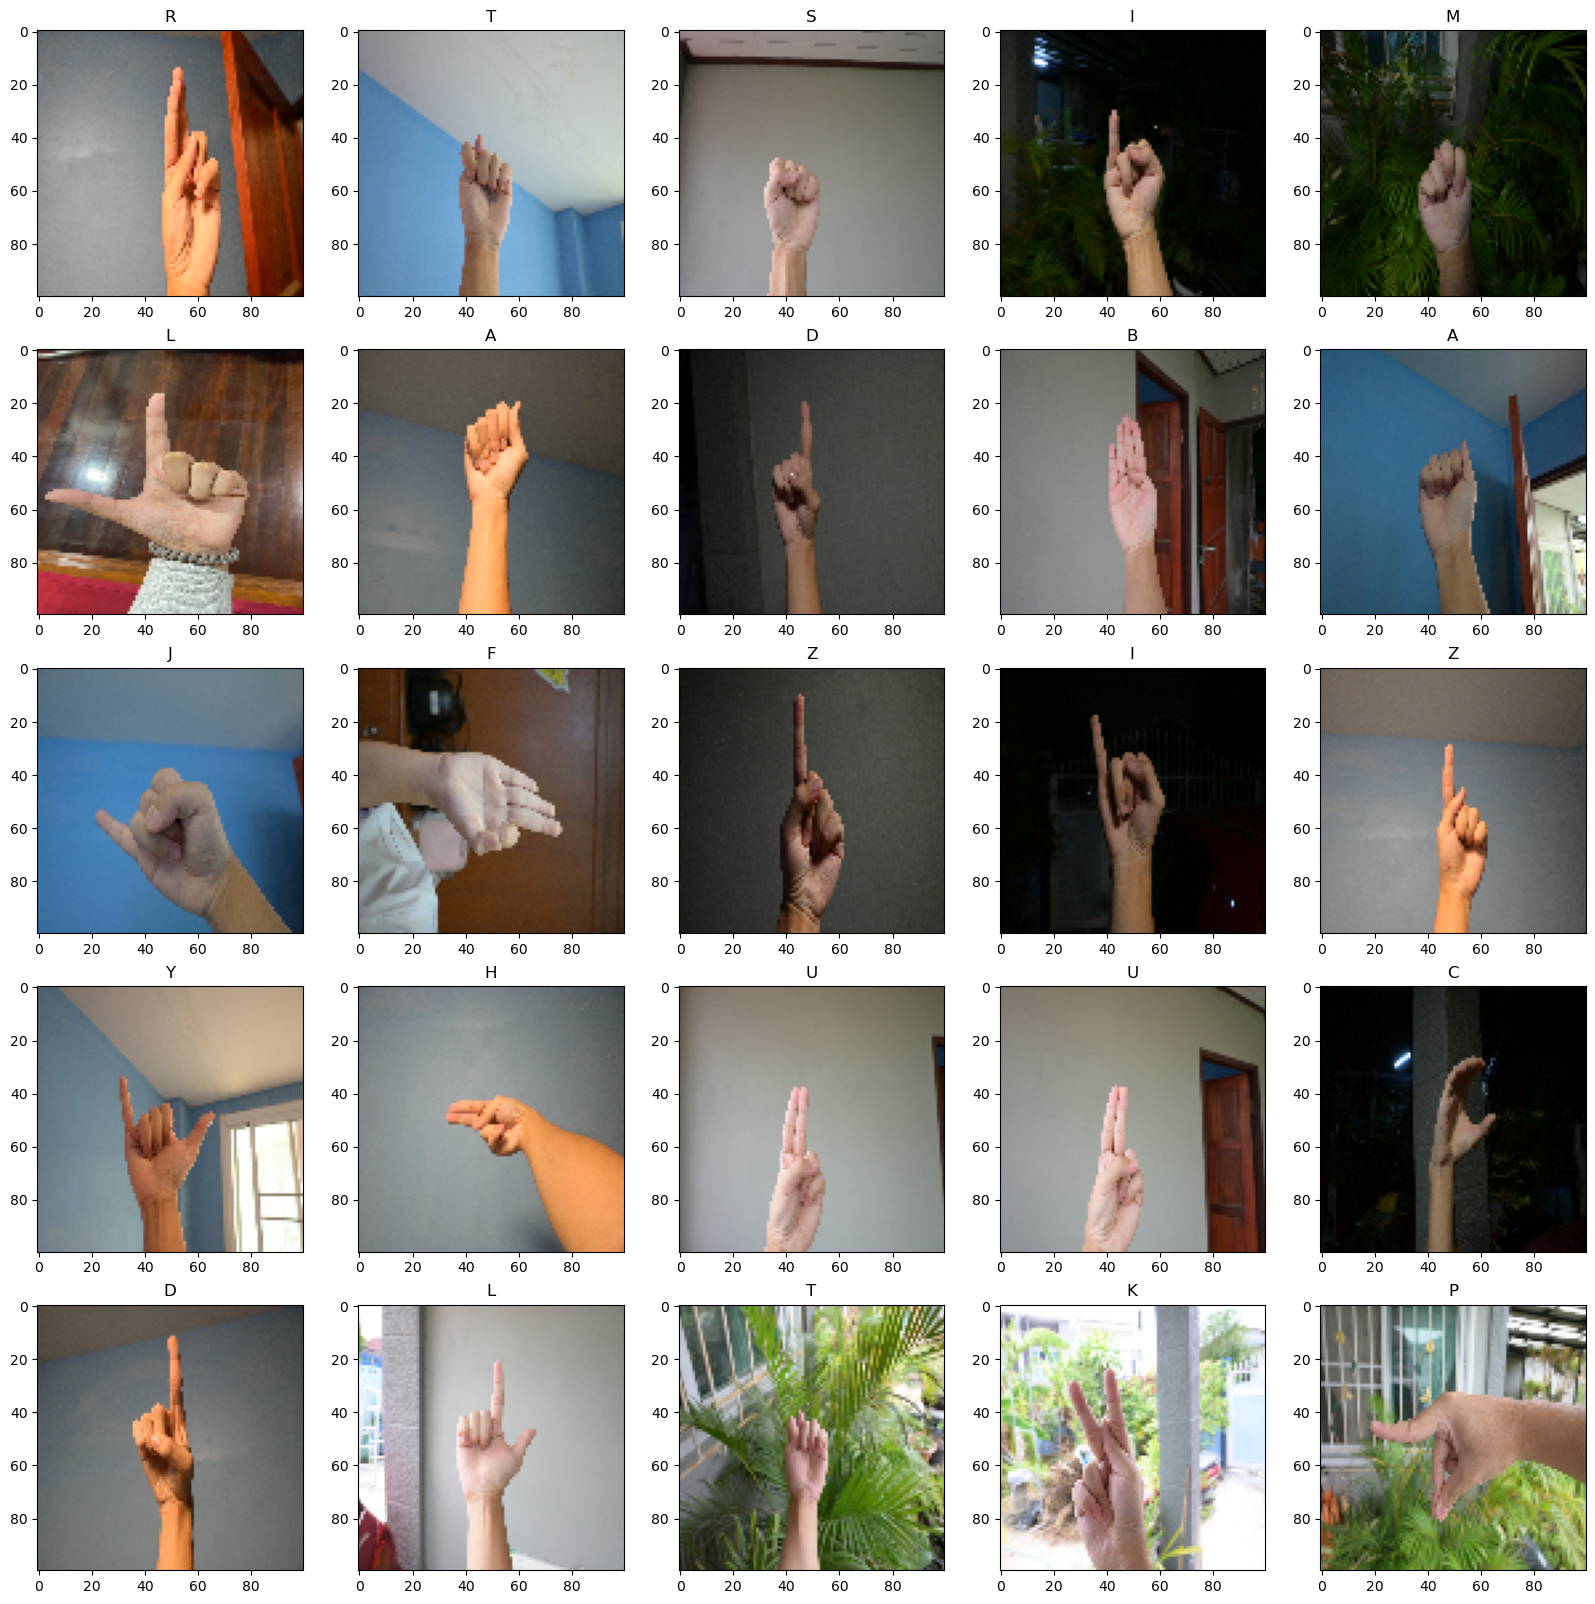

In [60]:
row, col = 5, 5
fig, axes = plt.subplots(row, col, figsize=(20, 20))        
for images, labels in train_ds.take(1):
    for i in range(row * col):
        ax = plt.subplot(5, 5, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(classnames[labels[i]])

In [23]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [24]:
clf = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255),
    tf.keras.layers.Conv2D(64, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(128, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(256, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(len(classnames))
])


In [25]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

train_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y))

In [26]:
clf.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [54]:
epochs = 10
clf.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
)

Epoch 1/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 14s 161ms/step - accuracy: 0.8780 - loss: 0.3688 - val_accuracy: 0.9724 - val_loss: 0.1019
Epoch 2/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 14s 160ms/step - accuracy: 0.8776 - loss: 0.3414 - val_accuracy: 0.9695 - val_loss: 0.1130
Epoch 3/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 14s 160ms/step - accuracy: 0.8704 - loss: 0.3466 - val_accuracy: 0.9680 - val_loss: 0.1177
Epoch 4/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 14s 158ms/step - accuracy: 0.8704 - loss: 0.4014 - val_accuracy: 0.9709 - val_loss: 0.0972
Epoch 5/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 14s 163ms/step - accuracy: 0.8633 - loss: 0.4113 - val_accuracy: 0.9680 - val_loss: 0.1111
Epoch 6/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 14s 165ms/step - accuracy: 0.8791 - loss: 0.3450 - val_accuracy: 0.9767 - val_loss: 0.1072
Epoch 7/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 14s 162ms/step - accuracy: 0.8741 - loss: 0.3605 - val_accuracy: 0.9753 - val_loss: 0.1002
Epoch 8/10
87/87 ━━━━━━━━━━━━━━━━━━━━ 14s 165ms/step - accuracy: 0.8844 - loss: 0.3201 - val_accu

In [44]:
clf.save('sign_cnn_model.keras')
print("Model saved as sign_cnn_model.keras")

Model saved as sign_cnn_model.keras


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step


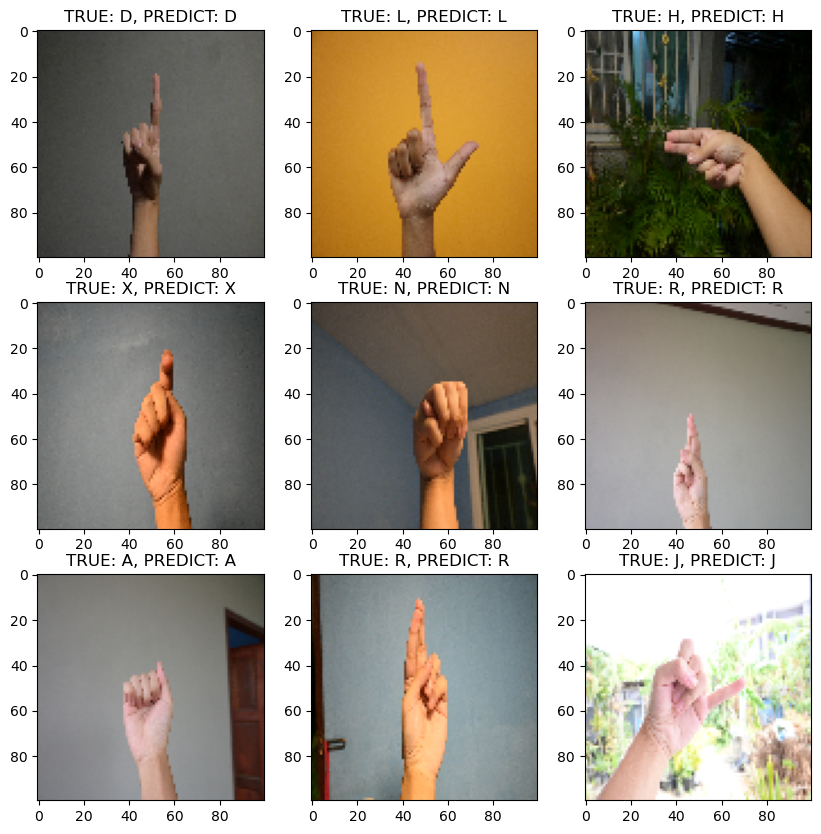

In [62]:
plt.figure(figsize=(10, 10))
for images, labels in val_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        preds = clf.predict(images)
        pred = tf.argmax(tf.nn.softmax(preds[i]), 0)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(f'TRUE: {classnames[labels[i]]}, PREDICT: {classnames[pred]}')

In [82]:
def predict_sign(img_file):
    image = tf.keras.utils.load_img(img_file)
    image = image.resize((img_width, img_height))
    input_arr = tf.keras.utils.img_to_array(image)
    input_arr = np.array([input_arr])  # Convert single image to a batch
    predictions = clf.predict(input_arr)
    top = tf.argmax(tf.nn.softmax(predictions), 1)
    return classnames[top[0]]

In [84]:
def detect_sign(model, size, img_file):
    img = image.load_img(img_file, target_size=size)  # resize ให้ตรงกับโมเดล
    plt.imshow(img)
    plt.show()

    input_arr = image.img_to_array(img) / 255.0  # normalize
    print(f"Input shape: {input_arr.shape}")     # ตรวจสอบขนาดภาพ
    input_arr = np.expand_dims(input_arr, axis=0)  # เพิ่ม batch dimension

    predictions = model.predict(input_arr)
    top = tf.argmax(tf.nn.softmax(predictions), axis=1)
    return classnames[top[0]]

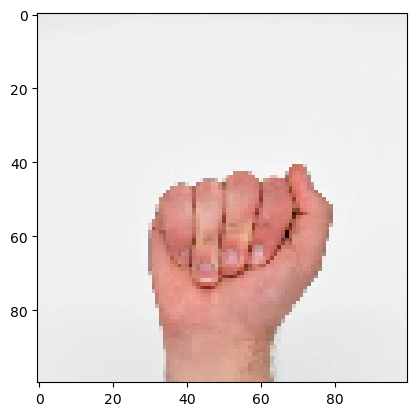

Input shape: (100, 100, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


In [86]:
img_width, img_height = 100, 100

# ทดสอบฟังก์ชัน detect_sign
image_path = "C:/Users/ohmomega/Desktop/AI/dataset/test/A1_test.jpg"  # เปลี่ยนเป็นภาพที่ต้องการทดสอบ
predicted_letter = detect_sign(clf, (img_width, img_height), image_path)

In [90]:
# แสดงผลลัพธ์ในคอนโซล
print(f"AI ทำนายว่า: {predicted_letter}")

AI ทำนายว่า: B


In [ ]:
from PIL import Image
image_path = "C:/Users/ohmomega/Desktop/AI/dataset/test/A1_test.jpg"
img = Image.open(image_path)
img.show()  # ตรวจสอบว่าภาพโหลดถูกต้องหรือไม่